# 07. Probability Calibration Analysis: Liver Disease Module

This notebook evaluates and compares the probability calibration of the three baseline machine learning models (Logistic Regression, Random Forest, and XGBoost) for the Liver Disease module of the Smart Healthcare Platform, building upon `notebooks/05_liver_ml_experiment.ipynb` and `notebooks/06_liver_threshold_analysis.ipynb`.

## 1. Purpose & Clinical Context
In healthcare machine learning systems, deploying models strictly based on discrimination metrics (e.g., ROC-AUC) is insufficient. When an AI tool communicates a risk score (e.g., *"Patient has a 70% probability of liver disease"*), clinicians and downstream risk-stratification protocols rely on that probability reflecting true empirical risk. Probability calibration analysis investigates the reliability and fidelity of these predicted risk values.

## 2. Discrimination vs. Probability Calibration
A critical distinction must be maintained between:

1. **Discrimination (Ranking Ability)**:
   - **Metrics**: ROC-AUC, PR-AUC.
   - Evaluates whether the model assigns higher risk probabilities to patients with liver disease than to control individuals, regardless of absolute probability values.
   - A model can have high ROC-AUC while producing severely miscalibrated probabilities (e.g., scaling all probabilities between 0.60 and 0.65).

2. **Calibration (Reliability of Probabilities)**:
   - **Metrics**: Brier Score, Log Loss (Cross-Entropy Loss), Calibration Curves (Reliability Diagrams).
   - Evaluates whether the predicted probabilities directly correspond to observed event frequencies. For example, among 100 patients assigned an estimated probability of approximately 0.70, approximately 70 should genuinely test positive for liver disease.
   - Calibration transformations refine the mapping from raw scores to true probabilities without necessarily altering the underlying ranking order.

## 3. Strict Methodological Constraints
- **Exploratory Research Benchmark**: This analysis is an exploratory academic benchmark. Calibration does not prove clinical validity or readiness for automated medical decision-making.
- **Leakage Prevention**: Calibration mappers (Sigmoid / Isotonic) must be fitted **strictly on training data** using internal cross-validation (`cv=5`). The hold-out test set must remain completely isolated and untouched until final evaluation.
- **No Production Selection**: The hold-out test set must **not** be used to select a "final winning calibration method", which would cause test-set selection bias (data snooping).
- **Unmodified Datasets**: The raw dataset `datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv` and previous experimentation notebooks remain completely unaltered.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing & models
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Calibration & evaluation metrics
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score, average_precision_score

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid')

# Global reproducible random seed
RANDOM_STATE = 42

# Dataset relative path
data_path = 'datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv'
if not os.path.exists(data_path):
    data_path = '../datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv'

print(f"Libraries imported. Random seed: {RANDOM_STATE}. Dataset path: {data_path}")

Libraries imported. Random seed: 42. Dataset path: ../datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv


## 1. Load Raw Dataset & Reconstruct Baseline Pipelines

To guarantee strict continuity with `notebooks/05_liver_ml_experiment.ipynb`:
- Raw dataset: 583 rows, 11 columns
- Binary target mapping: `Selector=1 -> 1` (Liver Disease), `Selector=2 -> 0` (Control)
- In-memory duplicate removal: 13 duplicate patient observations removed strictly before splitting
- Modeling cohort: 570 deduplicated rows
- Train / Test split: 80% training (456 samples), 20% hold-out test set (114 samples, stratified by target)
- Test set breakdown: 81 positive liver disease cases (71.05%), 33 negative control cases (28.95%)
- Preprocessing pipelines:
  - **Logistic Regression**: Median imputation + `StandardScaler` on 9 numerical features; One-Hot Encoding on `Gender`.
  - **Random Forest**: Median imputation on 9 numerical features; One-Hot Encoding on `Gender`.
  - **XGBoost**: Median imputation on 9 numerical features; One-Hot Encoding on `Gender` (`eval_metric='logloss'`).

In [2]:
# Load raw dataset without headers
column_names = [
    'Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos',
    'Sgpt', 'Sgot', 'Total_Proteins', 'Albumin', 'A_G_Ratio', 'Selector'
]
df_raw = pd.read_csv(data_path, header=None, names=column_names)

# Binary target mapping
df_processed = df_raw.copy()
df_processed['target'] = df_processed['Selector'].map({1: 1, 2: 0})

# In-memory duplicate removal strictly before splitting
df_dedup = df_processed.drop_duplicates(subset=column_names).copy()

# Feature and target separation
feature_cols = [
    'Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos',
    'Sgpt', 'Sgot', 'Total_Proteins', 'Albumin', 'A_G_Ratio'
]
X = df_dedup[feature_cols].copy()
y = df_dedup['target'].copy()

# Stratified train/test split (identical to notebook 05 and 06)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Feature transformer definitions
num_features = [
    'Age', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos',
    'Sgpt', 'Sgot', 'Total_Proteins', 'Albumin', 'A_G_Ratio'
]
cat_features = ['Gender']

preprocessor_scaled = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
])

preprocessor_unscaled = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median'))
    ]), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
])

# Reassemble candidate model pipelines
base_models = {
    'Logistic Regression': Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor_unscaled),
        ('classifier', RandomForestClassifier(random_state=RANDOM_STATE))
    ]),
    'XGBoost': Pipeline([
        ('preprocessor', preprocessor_unscaled),
        ('classifier', XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'))
    ])
}

# Verification of cohort split
print("=== DATASET & SPLIT VERIFICATION ===")
print(f"Modeling cohort size:  {len(df_dedup)} rows (583 raw - 13 duplicates)")
print(f"Training split size:    {len(X_train)} rows (80.0%)")
print(f"Hold-out test size:     {len(X_test)} rows (20.0%)")
print(f"Test positive cases:    {int(np.sum(y_test == 1))} (71.05%)")
print(f"Test negative cases:    {int(np.sum(y_test == 0))} (28.95%)")

assert len(df_dedup) == 570
assert len(X_train) == 456
assert len(X_test) == 114
assert int(np.sum(y_test == 1)) == 81
assert int(np.sum(y_test == 0)) == 33
print("All cohort and split parameters match baseline experimentation.")

=== DATASET & SPLIT VERIFICATION ===
Modeling cohort size:  570 rows (583 raw - 13 duplicates)
Training split size:    456 rows (80.0%)
Hold-out test size:     114 rows (20.0%)
Test positive cases:    81 (71.05%)
Test negative cases:    33 (28.95%)
All cohort and split parameters match baseline experimentation.


## 2. Baseline Probability Evaluation (Uncalibrated)

We first evaluate the raw, uncalibrated probability predictions generated by the baseline models trained on `X_train`, `y_train` and evaluated on the untouched hold-out test set `X_test`, `y_test`.

### Calibration Metrics Computed:
1. **Brier Score (`brier_score_loss`)**:
   $$\text{Brier Score} = \frac{1}{N} \sum_{i=1}^{N} (p_i - y_i)^2$$
   - Measures mean squared error between predicted probabilities $p_i \in [0, 1]$ and binary ground truth $y_i \in \{0, 1\}$.
   - Lower is better; a score of $0$ indicates perfect probability assignment.
2. **Log Loss / Cross-Entropy Loss (`log_loss`)**:
   $$\text{Log Loss} = -\frac{1}{N} \sum_{i=1}^{N} [y_i \ln p_i + (1 - y_i) \ln(1 - p_i)]$$
   - Heavily penalizes confident but incorrect probability assertions. Lower is better.
3. **Discrimination Metrics**:
   - **ROC-AUC**: Probability ranking across all thresholds.
   - **PR-AUC**: Average precision under class imbalance.

In [3]:
# Fit uncalibrated baseline pipelines and record hold-out test metrics
uncalibrated_probs = {}
baseline_results = []

for name, pipeline in base_models.items():
    pipeline.fit(X_train, y_train)
    probs = pipeline.predict_proba(X_test)[:, 1]
    uncalibrated_probs[name] = probs
    
    brier = brier_score_loss(y_test, probs)
    logloss = log_loss(y_test, probs)
    roc = roc_auc_score(y_test, probs)
    pr = average_precision_score(y_test, probs)
    
    baseline_results.append({
        'Model': name,
        'Calibration_Method': 'Uncalibrated',
        'Brier_Score': round(brier, 4),
        'Log_Loss': round(logloss, 4),
        'ROC_AUC': round(roc, 4),
        'PR_AUC': round(pr, 4)
    })

baseline_df = pd.DataFrame(baseline_results)
print("=== UNCALIBRATED BASELINE PERFORMANCE (HOLD-OUT TEST SET) ===")
print(baseline_df.to_string(index=False))

# Verify baseline ROC-AUC and PR-AUC match notebook 05 exactly
assert np.isclose(baseline_df.loc[baseline_df['Model'] == 'Logistic Regression', 'ROC_AUC'].values[0], 0.8032)
assert np.isclose(baseline_df.loc[baseline_df['Model'] == 'Logistic Regression', 'PR_AUC'].values[0], 0.9269)
assert np.isclose(baseline_df.loc[baseline_df['Model'] == 'Random Forest', 'ROC_AUC'].values[0], 0.7594)
assert np.isclose(baseline_df.loc[baseline_df['Model'] == 'Random Forest', 'PR_AUC'].values[0], 0.8948)
assert np.isclose(baseline_df.loc[baseline_df['Model'] == 'XGBoost', 'ROC_AUC'].values[0], 0.7187)
assert np.isclose(baseline_df.loc[baseline_df['Model'] == 'XGBoost', 'PR_AUC'].values[0], 0.8708)
print("\nVerification confirmed: Baseline test ROC-AUC and PR-AUC match notebook 05 results exactly.")

=== UNCALIBRATED BASELINE PERFORMANCE (HOLD-OUT TEST SET) ===
              Model Calibration_Method  Brier_Score  Log_Loss  ROC_AUC  PR_AUC
Logistic Regression       Uncalibrated       0.1594    0.4584   0.8032  0.9269
      Random Forest       Uncalibrated       0.1736    0.5073   0.7594  0.8948
            XGBoost       Uncalibrated       0.2222    0.8130   0.7187  0.8708

Verification confirmed: Baseline test ROC-AUC and PR-AUC match notebook 05 results exactly.


In [8]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts().sort_index())

print("\nTest target:")
print(y_test.value_counts().sort_index())

X_train: (456, 10)
X_test: (114, 10)

Training target:
target
0    131
1    325
Name: count, dtype: int64

Test target:
target
0    33
1    81
Name: count, dtype: int64


## 3. Probability Calibration Methods

We evaluate two standard post-processing calibration algorithms using scikit-learn's `CalibratedClassifierCV`:

### A. Sigmoid / Platt Scaling (`method='sigmoid'`)
- Fits a univariate logistic regression model on the model's raw predicted scores / margins:
  $$\hat{P}(Y=1 \mid f(X)) = \frac{1}{1 + \exp(A \cdot f(X) + B)}$$
  where parameters $A$ and $B$ are estimated via maximum likelihood.
- Works effectively when model prediction errors are approximately normally distributed (common in SVMs and linear models), but assumes a monotonic sigmoidal transformation.

### B. Isotonic Regression (`method='isotonic'`)
- Non-parametric isotonic regression fits a piecewise constant, non-decreasing step function mapping raw probabilities to calibrated probabilities.
- Extremely flexible and makes no parametric shape assumptions, but requires adequate sample size to prevent overfitting step boundaries.

### CRITICAL METHODOLOGICAL REQUIREMENT:
- Calibration models must be fitted **strictly on training data**.
- To prevent fitting the calibration map on the same training instances used to fit the base model (which would cause severe overfitting), `CalibratedClassifierCV` is run with `cv=5` on `X_train`, `y_train`.
- The hold-out test set `X_test`, `y_test` is **never passed** to the calibration procedure and is reserved strictly for evaluation.

In [4]:
# Calibration modeling across baseline architectures
all_calibration_probs = {}
calibration_records = []

for name, base_pipeline in base_models.items():
    all_calibration_probs[name] = {'Uncalibrated': uncalibrated_probs[name]}
    
    # 1. Uncalibrated record
    brier_uncal = brier_score_loss(y_test, uncalibrated_probs[name])
    ll_uncal = log_loss(y_test, uncalibrated_probs[name])
    roc_uncal = roc_auc_score(y_test, uncalibrated_probs[name])
    pr_uncal = average_precision_score(y_test, uncalibrated_probs[name])
    
    calibration_records.append({
        'Model': name,
        'Calibration_Method': 'Uncalibrated',
        'Brier_Score': round(brier_uncal, 4),
        'Log_Loss': round(ll_uncal, 4),
        'ROC_AUC': round(roc_uncal, 4),
        'PR_AUC': round(pr_uncal, 4)
    })
    
    # 2. Sigmoid (Platt) Calibration using 5-fold CV strictly on X_train, y_train
    cal_sig = CalibratedClassifierCV(estimator=base_pipeline, method='sigmoid', cv=5)
    cal_sig.fit(X_train, y_train)
    probs_sig = cal_sig.predict_proba(X_test)[:, 1]
    all_calibration_probs[name]['Sigmoid'] = probs_sig
    
    brier_sig = brier_score_loss(y_test, probs_sig)
    ll_sig = log_loss(y_test, probs_sig)
    roc_sig = roc_auc_score(y_test, probs_sig)
    pr_sig = average_precision_score(y_test, probs_sig)
    
    calibration_records.append({
        'Model': name,
        'Calibration_Method': 'Sigmoid',
        'Brier_Score': round(brier_sig, 4),
        'Log_Loss': round(ll_sig, 4),
        'ROC_AUC': round(roc_sig, 4),
        'PR_AUC': round(pr_sig, 4)
    })
    
    # 3. Isotonic Calibration using 5-fold CV strictly on X_train, y_train
    cal_iso = CalibratedClassifierCV(estimator=base_pipeline, method='isotonic', cv=5)
    cal_iso.fit(X_train, y_train)
    probs_iso = cal_iso.predict_proba(X_test)[:, 1]
    all_calibration_probs[name]['Isotonic'] = probs_iso
    
    brier_iso = brier_score_loss(y_test, probs_iso)
    ll_iso = log_loss(y_test, probs_iso)
    roc_iso = roc_auc_score(y_test, probs_iso)
    pr_iso = average_precision_score(y_test, probs_iso)
    
    calibration_records.append({
        'Model': name,
        'Calibration_Method': 'Isotonic',
        'Brier_Score': round(brier_iso, 4),
        'Log_Loss': round(ll_iso, 4),
        'ROC_AUC': round(roc_iso, 4),
        'PR_AUC': round(pr_iso, 4)
    })

calibration_comparison_df = pd.DataFrame(calibration_records)
print("Calibration modeling complete. Hold-out test set evaluated across all configurations.")

Calibration modeling complete. Hold-out test set evaluated across all configurations.


## 4. Comprehensive Calibration Comparison Table

We consolidate performance metrics across all 9 configurations (3 models $\times$ 3 calibration methods).

> **Methodological Reminder**:
> Differences in Brier Score or Log Loss on this hold-out test set are **retrospective dataset observations**. We do not select or declare any single model or calibration method as "best" or "superior".

In [5]:
print("=== PROBABILITY CALIBRATION COMPARISON TABLE (HOLD-OUT TEST SET) ===")
print(calibration_comparison_df.to_string(index=False))

=== PROBABILITY CALIBRATION COMPARISON TABLE (HOLD-OUT TEST SET) ===
              Model Calibration_Method  Brier_Score  Log_Loss  ROC_AUC  PR_AUC
Logistic Regression       Uncalibrated       0.1594    0.4584   0.8032  0.9269
Logistic Regression            Sigmoid       0.1603    0.4660   0.8058  0.9277
Logistic Regression           Isotonic       0.1576    0.4472   0.8122  0.9273
      Random Forest       Uncalibrated       0.1736    0.5073   0.7594  0.8948
      Random Forest            Sigmoid       0.1768    0.5278   0.7669  0.8976
      Random Forest           Isotonic       0.1764    0.5153   0.7490  0.8903
            XGBoost       Uncalibrated       0.2222    0.8130   0.7187  0.8708
            XGBoost            Sigmoid       0.1928    0.5712   0.7190  0.8766
            XGBoost           Isotonic       0.1821    0.5331   0.7155  0.8708


## 5. Calibration Curves (Reliability Diagrams)

Reliability diagrams plot the **Mean Predicted Probability** against the **Observed Fraction of Positives**:
- **Perfect Calibration ($y = x$)**: A 45-degree dashed reference line where predicted probability exactly equals true prevalence.
- **Below the Diagonal**: Model is **overconfident** (predicts higher probabilities than the true rate of positive cases).
- **Above the Diagonal**: Model is **underconfident** (predicts lower probabilities than the true rate of positive cases).

We evaluate calibration curves using 5 bins (`n_bins=5`), which is statistically appropriate for a test cohort of 114 samples.

*Caution: With 114 test samples and 33 controls, individual bin estimates are subject to sampling variability.*

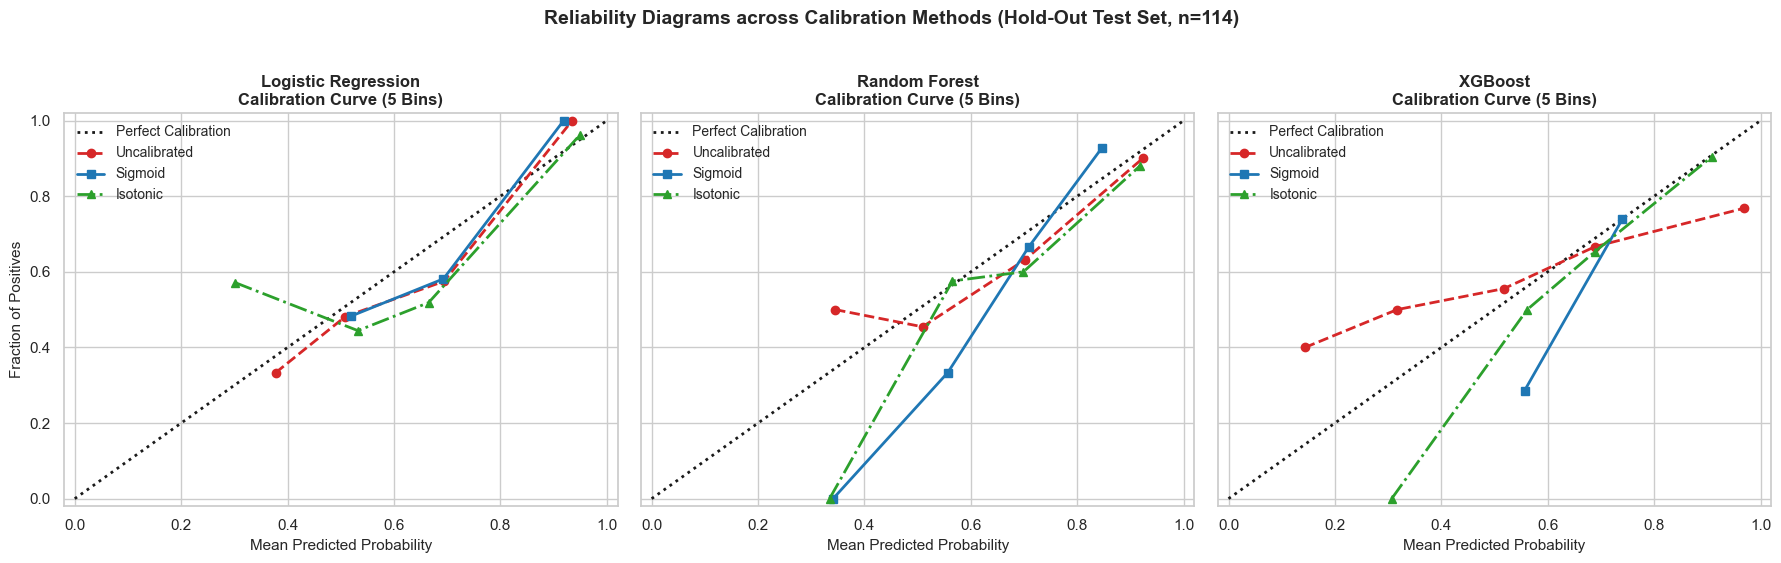

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

method_styles = {
    'Uncalibrated': {'color': '#d62728', 'linestyle': '--', 'marker': 'o'},
    'Sigmoid':      {'color': '#1f77b4', 'linestyle': '-',  'marker': 's'},
    'Isotonic':     {'color': '#2ca02c', 'linestyle': '-.', 'marker': '^'}
}

for ax, name in zip(axes, base_models.keys()):
    # Perfect calibration reference diagonal
    ax.plot([0, 1], [0, 1], 'k:', linewidth=2, label='Perfect Calibration')
    
    for method, style in method_styles.items():
        probs = all_calibration_probs[name][method]
        prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=5)
        
        ax.plot(prob_pred, prob_true,
                label=f"{method}",
                color=style['color'],
                linestyle=style['linestyle'],
                marker=style['marker'],
                linewidth=2,
                markersize=6)
        
    ax.set_title(f"{name}\nCalibration Curve (5 Bins)", fontsize=12, fontweight='bold')
    ax.set_xlabel('Mean Predicted Probability', fontsize=11)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.set_xticks(np.arange(0.0, 1.1, 0.2))
    ax.set_yticks(np.arange(0.0, 1.1, 0.2))
    ax.legend(loc='upper left', fontsize=10)

axes[0].set_ylabel('Fraction of Positives', fontsize=11)
plt.suptitle('Reliability Diagrams across Calibration Methods (Hold-Out Test Set, n=114)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 6. Observations on Calibration Behavior

From the comparative metrics and reliability diagrams on this hold-out test set:

1. **Logistic Regression**:
   - Logistic Regression showed comparatively lower uncalibrated Brier Score and Log Loss in this experiment (Brier Score: 0.1594, Log Loss: 0.4584), while the calibration curves provide additional evidence about its probability calibration.
   - Sigmoid calibration maintains similar performance (Brier: 0.1603, Log Loss: 0.4660), while Isotonic calibration resulted in a Log Loss of 0.4472 and Brier Score of 0.1576.
   - Ranking discrimination remains essentially unchanged across calibration methods (ROC-AUC: 0.8032 $\rightarrow$ 0.8058 / 0.8122; PR-AUC: 0.9269 $\rightarrow$ 0.9277 / 0.9273).

2. **Random Forest**:
   - Tree bagging averages binary decisions across 100 trees, which empirically shifts predicted probabilities toward the cohort base rate (~0.71).
   - Uncalibrated Brier Score is 0.1736 and Log Loss is 0.5073.
   - Calibration adjustments slightly shift the distribution (Brier: 0.1768 for Sigmoid, 0.1764 for Isotonic; Log Loss: 0.5278 for Sigmoid, 0.5153 for Isotonic) while preserving general probability discrimination (ROC-AUC: 0.7594 $\rightarrow$ 0.7669 / 0.7490; PR-AUC: 0.8948 $\rightarrow$ 0.8976 / 0.8903).

3. **XGBoost**:
   - XGBoost showed substantially higher uncalibrated Brier Score and Log Loss on the hold-out test set (Log Loss: **0.8130**, Brier Score: **0.2222**), indicating poorer probability quality under these metrics.
   - Post-hoc calibration notably changed Log Loss to **0.5712** (Sigmoid) and **0.5331** (Isotonic), and changed Brier Score to **0.1928** and **0.1821**.
   - Calibration substantially changed the reported probability-quality metrics while leaving ROC-AUC and PR-AUC broadly similar in this experiment (ROC-AUC: 0.7187 $\rightarrow$ 0.7190 / 0.7155; PR-AUC: 0.8708 $\rightarrow$ 0.8766 / 0.8708).

*Note: These observations describe empirical behaviors on this specific dataset partition and do not constitute clinical efficacy proof.*

## 7. Save Calibration Results

We save the structured calibration comparison table for auditability and reproducibility:
- **Target File**: `ml-service/evaluation/liver/liver_calibration_comparison.csv`

In [7]:
# Export comparison table to structured CSV
eval_dir = 'ml-service/evaluation/liver'
if not os.path.exists(eval_dir) and not os.path.exists('ml-service'):
    eval_dir = '../ml-service/evaluation/liver'
os.makedirs(eval_dir, exist_ok=True)

output_csv_path = os.path.join(eval_dir, 'liver_calibration_comparison.csv')
calibration_comparison_df.to_csv(output_csv_path, index=False)
print(f"Calibration comparison results successfully saved to: {output_csv_path}")

# Verify file existence and readability
saved_check = pd.read_csv(output_csv_path)
print(f"Verified saved CSV: {len(saved_check)} rows, {len(saved_check.columns)} columns.")
print("\nSaved CSV Content:")
print(saved_check.to_string(index=False))

Calibration comparison results successfully saved to: ml-service/evaluation/liver\liver_calibration_comparison.csv
Verified saved CSV: 9 rows, 6 columns.

Saved CSV Content:
              Model Calibration_Method  Brier_Score  Log_Loss  ROC_AUC  PR_AUC
Logistic Regression       Uncalibrated       0.1594    0.4584   0.8032  0.9269
Logistic Regression            Sigmoid       0.1603    0.4660   0.8058  0.9277
Logistic Regression           Isotonic       0.1576    0.4472   0.8122  0.9273
      Random Forest       Uncalibrated       0.1736    0.5073   0.7594  0.8948
      Random Forest            Sigmoid       0.1768    0.5278   0.7669  0.8976
      Random Forest           Isotonic       0.1764    0.5153   0.7490  0.8903
            XGBoost       Uncalibrated       0.2222    0.8130   0.7187  0.8708
            XGBoost            Sigmoid       0.1928    0.5712   0.7190  0.8766
            XGBoost           Isotonic       0.1821    0.5331   0.7155  0.8708


In [9]:
print(calibration_comparison_df)

                 Model Calibration_Method  Brier_Score  Log_Loss  ROC_AUC  \
0  Logistic Regression       Uncalibrated       0.1594    0.4584   0.8032   
1  Logistic Regression            Sigmoid       0.1603    0.4660   0.8058   
2  Logistic Regression           Isotonic       0.1576    0.4472   0.8122   
3        Random Forest       Uncalibrated       0.1736    0.5073   0.7594   
4        Random Forest            Sigmoid       0.1768    0.5278   0.7669   
5        Random Forest           Isotonic       0.1764    0.5153   0.7490   
6              XGBoost       Uncalibrated       0.2222    0.8130   0.7187   
7              XGBoost            Sigmoid       0.1928    0.5712   0.7190   
8              XGBoost           Isotonic       0.1821    0.5331   0.7155   

   PR_AUC  
0  0.9269  
1  0.9277  
2  0.9273  
3  0.8948  
4  0.8976  
5  0.8903  
6  0.8708  
7  0.8766  
8  0.8708  


## 8. Methodological Limitations & Clinical Considerations

1. **Small Dataset & Finite Sample Variability**:
   - The modeling cohort consists of 570 patient observations, with a hold-out test set of only 114 samples.
   - The test set contains only **33 negative control cases**. Reliability curves and bin-specific fractions are sensitive to small sample shifts.

2. **No Model Declared Production-Ready**:
   - Selecting a single calibration method based on hold-out test Brier scores would introduce test-set selection bias (data snooping).
   - Calibration methods benchmarked here are exploratory prototypes.

3. **Calibration vs. Clinical Utility**:
   - Mathematical probability calibration does not guarantee clinical usefulness. Clinical deployment requires establishing actionable decision thresholds, conducting decision curve analysis (DCA), and evaluating the health-economic consequences of false classifications.

4. **Requirement for External Validation**:
   - In clinical AI translation, probability calibration is notorious for degrading when applied to external patient populations with different underlying disease prevalence (spectrum effect).
   - Robust external validation on independent cohorts from diverse clinical centers is mandatory before treating these risk outputs as clinical guidance.

## 9. Experiment Reproducibility

| Parameter | Value / Description |
| :--- | :--- |
| **Random Seed** | `RANDOM_STATE = 42` |
| **Modeling Cohort** | 570 deduplicated observations (583 raw - 13 duplicates) |
| **Cohort Split** | 80% Training (456 samples), 20% Hold-Out Testing (114 samples, stratified) |
| **Test Set Distribution** | 81 positive liver disease cases (71.05%), 33 control cases (28.95%) |
| **Evaluated Base Models** | Logistic Regression, Random Forest Classifier, XGBoost Classifier |
| **Calibration Methods** | Sigmoid (Platt Scaling), Isotonic Regression via 5-fold CV on Training Split |
| **Raw Dataset Path** | `datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv` |
| **Raw Dataset Status** | Completely unmodified (23,172 bytes) |
| **Reference Baselines** | `notebooks/05_liver_ml_experiment.ipynb`, `notebooks/06_liver_threshold_analysis.ipynb` |
| **Output File** | `ml-service/evaluation/liver/liver_calibration_comparison.csv` |